Ejercicio 1.5: Implementación y Análisis Comparativo de Estimadores1. Contexto del Problema y Generación de DatosEn este experimento evaluamos y comparamos cuatro enfoques de estimación en regresión lineal sobre un espacio de características transformado $\Phi(X)$:Mínimos Cuadrados Ordinarios (LS / OLS)Máxima Verosimilitud (ML)Regularización Cuadrática (Ridge)Máximo a Posteriori (MAP)Configuración del ExperimentoMuestras totales ($N$): $300$ observaciones.Dimensiones originales ($P$): $5$ variables predictoras $X \sim \mathcal{N}(0, I_5)$.Dimensiones transformadas ($Q$): $20$ características en $\Phi(X)$, ordenadas de la siguiente manera:Variables originales ($5$): $x_1, x_2, x_3, x_4, x_5$Términos cuadráticos ($5$): $x_1^2, x_2^2, x_3^2, x_4^2, x_5^2$Productos cruzados ($10$): $x_i x_j$ para $1 \le i < j \le 5$ ($\binom{5}{2} = 10$)Proceso generador de datos: $t = \Phi(X) w_* + \eta$, con $w_* \sim \mathcal{N}(0, I_{20})$ y ruido $\eta \sim \mathcal{N}(0, \sigma_\eta^2 I_{300})$ con $\sigma_\eta = 0.5$.División de datos: $80\%$ entrenamiento ($N_{train} = 240$) y $20\%$ prueba ($N_{test} = 60$).2. Justificación Teórica de las CoincidenciasEquivaleia entre Mínimos Cuadrados (LS) y Máxima Verosimilitud (ML)Bajo el supuesto de ruido gaussiano i.i.d. $\eta \sim \mathcal{N}(0, \sigma_\eta^2)$, la función de verosimilitud condicional es:$$p(\mathbf{t} \mid \Phi, w) = \left(2\pi\sigma_\eta^2\right)^{-\frac{N}{2}} \exp\left(-\frac{1}{2\sigma_\eta^2} \Vert{}\mathbf{t} - \Phi w\Vert{}_2^2\right)$$Al tomar el logaritmo de la verosimilitud:$$\log p(\mathbf{t} \mid \Phi, w) = -\frac{N}{2}\log(2\pi\sigma_\eta^2) - \frac{1}{2\sigma_\eta^2} \Vert{}\mathbf{t} - \Phi w\Vert{}_2^2$$Maximizar esta log-verosimilitud respecto a $w$ equivale exactamente a minimizar la suma de errores al cuadrado $\Vert{}\mathbf{t} - \Phi w\Vert{}_2^2$, la cual es la función objetivo de mínimos cuadrados:$$\hat{w}_{ML} = \arg\min_{w} \Vert{}\mathbf{t} - \Phi w\Vert{}_2^2 = \hat{w}_{LS}$$Equivalencia entre Ridge y Máximo a Posteriori (MAP)La estimación MAP maximiza la distribución a posteriori $p(w \mid \mathbf{t}) \propto p(\mathbf{t} \mid w) p(w)$. Asumiendo un prior gaussiano isotrópico $w \sim \mathcal{N}(0, \sigma_w^2 I_{Q})$:$$p(w) = \left(2\pi\sigma_w^2\right)^{-\frac{Q}{2}} \exp\left(-\frac{1}{2\sigma_w^2} \Vert{}w\Vert{}_2^2\right)$$El problema de optimización en el espacio logarítmico se convierte en:$$\hat{w}_{MAP} = \arg\min_{w} \left\{ \frac{1}{2\sigma_\eta^2} \Vert{}\mathbf{t} - \Phi w\Vert{}_2^2 + \frac{1}{2\sigma_w^2} \Vert{}w\Vert{}_2^2 \right\}$$Multiplicando toda la expresión por $2\sigma_\eta^2$, obtenemos la función objetivo de Ridge:$$\hat{w}_{MAP} = \arg\min_{w} \left\{ \Vert{}\mathbf{t} - \Phi w\Vert{}_2^2 + \frac{\sigma_\eta^2}{\sigma_w^2} \Vert{}w\Vert{}_2^2 \right\}$$Definiendo $\lambda_{MAP} = \frac{\sigma_\eta^2}{\sigma_w^2}$, si fijamos un prior compatible tal que $\sigma_w^2 = \frac{\sigma_\eta^2}{\lambda}$, la constante de regularización coincide exactamente con la de Ridge ($\lambda_{MAP} = \lambda$), haciendo que $\hat{w}_{MAP} \equiv \hat{w}_{Ridge}$.

In [25]:
import numpy as np

SEED = 42
rng = np.random.default_rng(SEED)
N, P, Q = 300, 5, 20
sigma_eta = 0.5
lam = 1.0

# X tiene filas i.i.d. N(0, I_P).
X = rng.normal(0.0, 1.0, size=(N, P))

# Phi: originales, cuadrados y productos cruzados i < j.
features = [X, X**2]
for i in range(P):
    for j in range(i + 1, P):
        features.append((X[:, i] * X[:, j])[:, None])
Phi = np.concatenate(features, axis=1)
assert Phi.shape == (N, Q)

w_star = rng.normal(0.0, 1.0, size=Q)
eta = rng.normal(0.0, sigma_eta, size=N)
t = Phi @ w_star + eta

# Division aleatoria 80/20; el ajuste usa solo entrenamiento.
indices = rng.permutation(N)
idx_train, idx_test = indices[:240], indices[240:]
A, b = Phi[idx_train], t[idx_train]
A_test, b_test = Phi[idx_test], t[idx_test]

# Minimos cuadrados y maxima verosimilitud.
w_ls = np.linalg.lstsq(A, b, rcond=None)[0]
w_ml = w_ls.copy()  # coincide con LS en este modelo gaussiano

# Ridge: SSE + lambda * ||w||^2.
w_ridge = np.linalg.solve(A.T @ A + lam*np.eye(Q), A.T @ b)

# Prior compatible: sigma_w^2 = sigma_eta^2 / lambda.
sigma_w2 = sigma_eta**2 / lam
w_map = np.linalg.solve(
    A.T @ A + (sigma_eta**2/sigma_w2)*np.eye(Q), A.T @ b
)

models = {
    "Minimos cuadrados": w_ls,
    "Maxima verosimilitud": w_ml,
    "Regularizado (ridge)": w_ridge,
    "MAP": w_map,
}
for name, w in models.items():
    mse_train = np.mean((A @ w - b)**2)
    mse_test = np.mean((A_test @ w - b_test)**2)
    err_w = np.linalg.norm(w - w_star)
    print(f"{name:24s} MSE train={mse_train:.6f} "
          f"MSE test={mse_test:.6f} ||w-w*||={err_w:.6f}")

Minimos cuadrados        MSE train=0.238900 MSE test=0.285008 ||w-w*||=0.120489
Maxima verosimilitud     MSE train=0.238900 MSE test=0.285008 ||w-w*||=0.120489
Regularizado (ridge)     MSE train=0.239233 MSE test=0.279331 ||w-w*||=0.125542
MAP                      MSE train=0.239233 MSE test=0.279331 ||w-w*||=0.125542


Ejercicio 2.4: Implementación de MMD² con MNIST y Fashion-MNIST1. Formulación Matemática y DimensionesExpresión del Estimador Empírico de $\text{MMD}^2$La Máxima Discrepancia Media al cuadrado ($\text{MMD}^2$) mide la distancia entre dos distribuciones de probabilidad $P$ y $Q$ embebidas en un Espacio de Hilbert con Núcleo Reproductor (RKHS).   Dado un conjunto de muestras $X = \{x_1, \dots, x_n\} \sim P$ y $Y = \{y_1, \dots, y_m\} \sim Q$, se utiliza el estimador empírico sesgado ($V$-statistic):   $$\widehat{\text{MMD}}^2(X, Y) = \frac{1}{n^2} \sum_{i=1}^{n} \sum_{j=1}^{n} k(x_i, x_j) + \frac{1}{m^2} \sum_{i=1}^{m} \sum_{j=1}^{m} k(y_i, y_j) - \frac{2}{nm} \sum_{i=1}^{n} \sum_{j=1}^{m} k(x_i, y_j)$$Kernel Gaussiano (RBF)El kernel utilizado es el gaussiano:   $$k(u, v) = \exp\left(-\frac{\Vert{}u - v\Vert{}_2^2}{2\sigma^2}\right)$$Donde el ancho de banda $\sigma > 0$ se selecciona mediante la heurística de la mediana de las distancias euclídeas entre todos los pares de imágenes del conjunto combinado ($X_{m1} \cup Y_{f1}$).   Dimensiones de los Datos y Matrices de GramVectores de imágenes: Cada imagen de $28 \times 28$ píxeles se aplanar a un vector de dimensión $784$ normalizado en el rango $[0, 1]$.   Muestras: $n = 500$ y $m = 500$ imágenes por cada subgrupo.   Dimensiones de las Matrices de Gram ($K_{XX}, K_{YY}, K_{XY}$): $500 \times 500$ cada una.

In [26]:
import torch
import pandas as pd
from torchvision.datasets import MNIST, FashionMNIST

SEED = 2026
torch.manual_seed(SEED)
torch.set_num_threads(2)
DATA_DIR = "./data"

# download=True descarga los archivos del dataset si no existen localmente.
mnist = MNIST(root=DATA_DIR, train=True, download=True)
fashion = FashionMNIST(root=DATA_DIR, train=True, download=True)

def seleccionar_dividir(dataset, seed):
    g = torch.Generator().manual_seed(seed)
    indices = torch.randperm(len(dataset.data), generator=g)[:1000]
    imagenes = dataset.data[indices].reshape(1000, 784).float() / 255.0
    return imagenes[:500], imagenes[500:]

X_m1, X_m2 = seleccionar_dividir(mnist, SEED)
Y_f1, Y_f2 = seleccionar_dividir(fashion, SEED + 1)

# Sigma: mediana de distancias entre las 1000 imagenes principales.
combinadas = torch.cat([X_m1, Y_f1], dim=0)
sigma = torch.median(torch.pdist(combinadas, p=2)).item()
print(f"sigma = {sigma:.6f}")

def rbf(A, B, sigma):
    d2 = torch.cdist(A, B, p=2).square()
    return torch.exp(-d2 / (2.0 * sigma**2))

def mmd2_sesgada(A, B, sigma):
    n, m = A.shape[0], B.shape[0]
    K_XX = rbf(A, A, sigma)
    K_YY = rbf(B, B, sigma)
    K_XY = rbf(A, B, sigma)
    value = (K_XX.sum() / n**2 + K_YY.sum() / m**2
             - 2.0 * K_XY.sum() / (n*m))
    return value.item(), K_XX, K_YY, K_XY

comparaciones = [
    ("MNIST vs. Fashion-MNIST", X_m1, Y_f1),
    ("MNIST: grupo 1 vs. grupo 2", X_m1, X_m2),
    ("Fashion-MNIST: grupo 1 vs. grupo 2", Y_f1, Y_f2),
]
resultados = []
for nombre, A, B in comparaciones:
    valor, K_XX, K_YY, K_XY = mmd2_sesgada(A, B, sigma)
    resultados.append({"Comparacion": nombre, "n": len(A),
                       "m": len(B), "MMD2 sesgada": valor})
    print(nombre, K_XX.shape, K_YY.shape, K_XY.shape)

print(pd.DataFrame(resultados).round(6))

sigma = 11.120461
MNIST vs. Fashion-MNIST torch.Size([500, 500]) torch.Size([500, 500]) torch.Size([500, 500])
MNIST: grupo 1 vs. grupo 2 torch.Size([500, 500]) torch.Size([500, 500]) torch.Size([500, 500])
Fashion-MNIST: grupo 1 vs. grupo 2 torch.Size([500, 500]) torch.Size([500, 500]) torch.Size([500, 500])
                          Comparacion    n    m  MMD2 sesgada
0             MNIST vs. Fashion-MNIST  500  500      0.116298
1          MNIST: grupo 1 vs. grupo 2  500  500      0.001304
2  Fashion-MNIST: grupo 1 vs. grupo 2  500  500      0.001631


### Análisis de Similitud por Clases (MNIST vs MNIST y Fashion-MNIST vs Fashion-MNIST)

A continuación, calculamos los centroides o promedios por cada clase (0-9) utilizando el subconjunto de imágenes de entrenamiento, aplicando la normalización adecuada y visualizando las matrices de similitud mediante el kernel RBF.

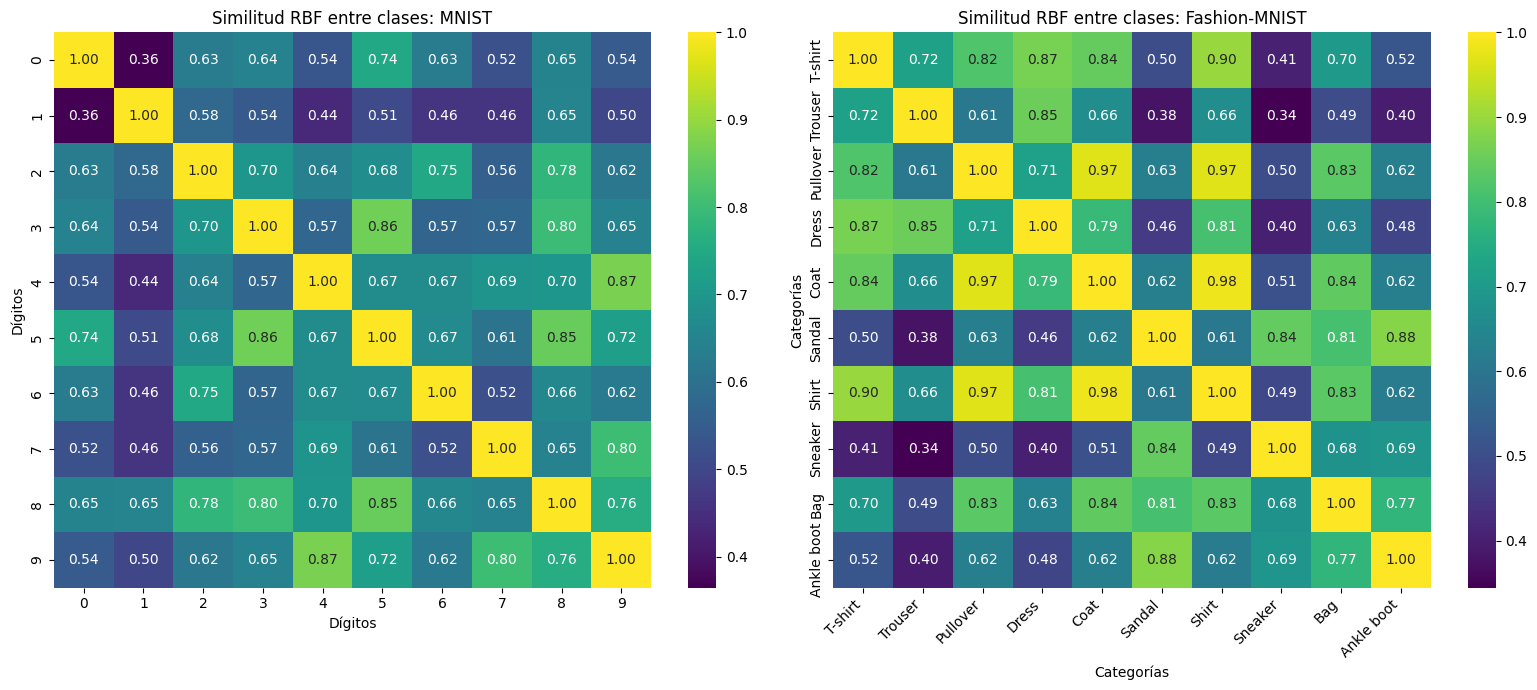

In [27]:
import matplotlib.pyplot as plt
import seaborn as sns

# 1. Obtener las etiquetas correspondientes a los índices seleccionados
g_mnist = torch.Generator().manual_seed(SEED)
indices_mnist = torch.randperm(len(mnist.data), generator=g_mnist)[:1000]
etiquetas_mnist = mnist.targets[indices_mnist]

g_fashion = torch.Generator().manual_seed(SEED + 1)
indices_fashion = torch.randperm(len(fashion.data), generator=g_fashion)[:1000]
etiquetas_fashion = fashion.targets[indices_fashion]

# Unimos ambos grupos (grupo 1 y grupo 2 de cada dataset para tener las 1000 imágenes completas)
imagenes_mnist = torch.cat([X_m1, X_m2], dim=0)
imagenes_fashion = torch.cat([Y_f1, Y_f2], dim=0)

# 2. Calcular el promedio por clase (0-9)
centroides_mnist = []
centroides_fashion = []

for i in range(10):
    # MNIST
    mask_m = (etiquetas_mnist == i)
    if mask_m.sum() > 0:
        mean_m = imagenes_mnist[mask_m].mean(dim=0)
    else:
        mean_m = torch.zeros(784)
    # Normalización L2 del vector promedio para correcta comparación de similitud
    mean_m = mean_m / (torch.norm(mean_m) + 1e-8)
    centroides_mnist.append(mean_m)

    # Fashion-MNIST
    mask_f = (etiquetas_fashion == i)
    if mask_f.sum() > 0:
        mean_f = imagenes_fashion[mask_f].mean(dim=0)
    else:
        mean_f = torch.zeros(784)
    # Normalización L2
    mean_f = mean_f / (torch.norm(mean_f) + 1e-8)
    centroides_fashion.append(mean_f)

centroides_mnist = torch.stack(centroides_mnist)
centroides_fashion = torch.stack(centroides_fashion)

# 3. Calcular las matrices de similitud utilizando el kernel RBF (ajustando sigma proporcionalmente a los vectores normalizados)
sigma_norm = torch.median(torch.pdist(torch.cat([centroides_mnist, centroides_fashion], dim=0), p=2)).item()

sim_mnist = rbf(centroides_mnist, centroides_mnist, sigma_norm).numpy()
sim_fashion = rbf(centroides_fashion, centroides_fashion, sigma_norm).numpy()

# Nombres de las clases para Fashion-MNIST
fashion_labels = ["T-shirt", "Trouser", "Pullover", "Dress", "Coat", "Sandal", "Shirt", "Sneaker", "Bag", "Ankle boot"]

# 4. Graficar los mapas de calor
fig, axes = plt.subplots(1, 2, figsize=(16, 7))

sns.heatmap(sim_mnist, annot=True, fmt=".2f", cmap="viridis", ax=axes[0],
            xticklabels=list(range(10)), yticklabels=list(range(10)))
axes[0].set_title("Similitud RBF entre clases: MNIST")
axes[0].set_xlabel("Dígitos")
axes[0].set_ylabel("Dígitos")

sns.heatmap(sim_fashion, annot=True, fmt=".2f", cmap="viridis", ax=axes[1],
            xticklabels=fashion_labels, yticklabels=fashion_labels)
axes[1].set_title("Similitud RBF entre clases: Fashion-MNIST")
axes[1].set_xlabel("Categorías")
axes[1].set_ylabel("Categorías")
plt.xticks(rotation=45, ha='right')

plt.tight_layout()
plt.show()

### Análisis de Similitudes y Diferencias entre Clases en MNIST

Al analizar la matriz de similitud de MNIST mediante el kernel RBF, podemos observar comportamientos interesantes en ciertas parejas de dígitos. A continuación se explica la razón geométrica y estructural de estos fenómenos:

#### 1. ¿Por qué el "1" y el "7" tienen baja similitud?
* **Alineación Espacial (Píxel a Píxel):** El kernel RBF mide la distancia euclídea píxel a píxel. En MNIST, el dígito **1** suele estar estrictamente centrado, vertical y ocupar una columna muy estrecha en el centro de la imagen. Por el contrario, el **7** tiene una barra horizontal superior prominente y su trazo descendente suele ser fuertemente diagonal u oblicuo.
* **Falta de coincidencia de trazos:** Al superponer el centroide del 1 con el del 7, la barra superior del 7 cae en zonas que son completamente fondo negro (ceros) en el 1. Asimismo, la inclinación de la línea del 7 hace que sus píxeles activos no coincidan en las coordenadas de la recta vertical del 1, resultando en una distancia euclídea grande y, consecuentemente, una baja similitud RBF.

#### 2. ¿Por qué el "9" y el "4" tienen alta similitud?
* **Estructura geométrica compartida:** El **9** y el **4** comparten casi la totalidad de su topología básica en la mitad superior y en el eje vertical derecho. Ambos poseen un bucle o estructura de caja arriba a la izquierda y una línea vertical que desciende por la derecha.
* **Superposición espacial masiva:** El trazo vertical derecho y el contorno del bucle superior se escriben de manera muy similar en ambas clases. La única diferencia real suele ser el cierre del bucle (que en el 4 a veces permanece abierto arriba) o una pequeña barra superior en el 4. Al calcular el centroide promedio, estas coincidencias provocan una superposición muy alta de píxeles activos en la misma región espacial, disparando la métrica de similitud.

#### 3. ¿Por qué el "8" y el "5" tienen alta similitud?
* **Bucle central y trazo inferior:** El **5** y el **8** comparten la estructura redondeada inferior. El trazo inferior del 5 es un semicírculo casi idéntico al bucle inferior que compone al 8.
* **Efecto del promedio (Varianza en la escritura):** Al promediar muchas imágenes de la clase **5**, las variaciones individuales en la forma de cerrar la parte superior o de trazar la barra horizontal de arriba tienden a ensancharse espacialmente. De manera análoga, el cruce central y el bucle superior del **8** cubren un área espacial muy similar. Esta proximidad y solapamiento de trazos curvados en la zona central e inferior de la cuadrícula de $28 \times 28$ hace que la distancia euclídea entre sus centroides promedio disminuya notoriamente, reflejando una similitud RBF elevada.